# Actors per data source over time

For each monthly snapshot, counts the actors that act only in the Git part of
the graph, only in the GitHub part, or in both.

In [1]:
import collections
import datetime as dt

import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from git2kg import Git2KG
from git2kg.export import NetworkXExporter

In [2]:
ARCHIVE = "mined-repos/tukaani-project_xz-git2kg.tar.gz"
FREQ = "ME"
# The repository's first issue is from 2022-12; before it every actor is Git
# only and the split says nothing
START = dt.datetime(2022, 10, 1, tzinfo=dt.timezone.utc)
FIGURE = "actor-sources.pdf"

# The relations a Git mine produces. Every other relation touching an actor
# comes from the GitHub API
GIT_VERBS = {"edit_add", "edit_delete", "author_commit", "committer_commit"}

COLOR = {"Git only": "#e87ba4", "both": "#eda100", "GitHub only": "#2a78d6"}

## Snapshots

In [3]:
kg = Git2KG.load(ARCHIVE)
kg.freq = FREQ
exports = NetworkXExporter().export_snapshots(kg.get_snapshots(processes=8))
print(f"{len(exports)} snapshots, {kg.actor_mapping['actor_id'].nunique()} actors")

Exporting Snapshots: 100%|██████████| 227/227 [00:13<00:00, 17.16it/s]

227 snapshots, 348 actors


## Counting

An actor counts as acting on a side if it is the subject of a relation of that
side in the snapshot. Being mentioned, assigned, or having a line edited is not
counted.

In [5]:
def sides_per_actor(graph) -> dict:
    """Maps each acting actor to the set of sides it acted on."""
    sides = collections.defaultdict(set)
    for source, _, data in graph.edges(data=True):
        subject, verb, _ = data["type"].split("__")
        if subject == "actor":
            sides[source].add("git" if verb in GIT_VERBS else "github")
    return sides


counts = []
for timestamp, graph in exports.items():
    if timestamp < START:
        continue
    tally = collections.Counter(
        "both" if len(s) == 2 else next(iter(s))
        for s in sides_per_actor(graph).values()
    )
    counts.append((timestamp, tally["git"], tally["github"], tally["both"]))

times = [c[0] for c in counts]
series = {
    "Git only": [c[1] for c in counts],
    "both": [c[3] for c in counts],
    "GitHub only": [c[2] for c in counts],
}
print(f"{len(counts)} snapshots from {times[0]:%Y-%m}")

49 snapshots from 2022-10


## Plot

Saved actor-sources.pdf


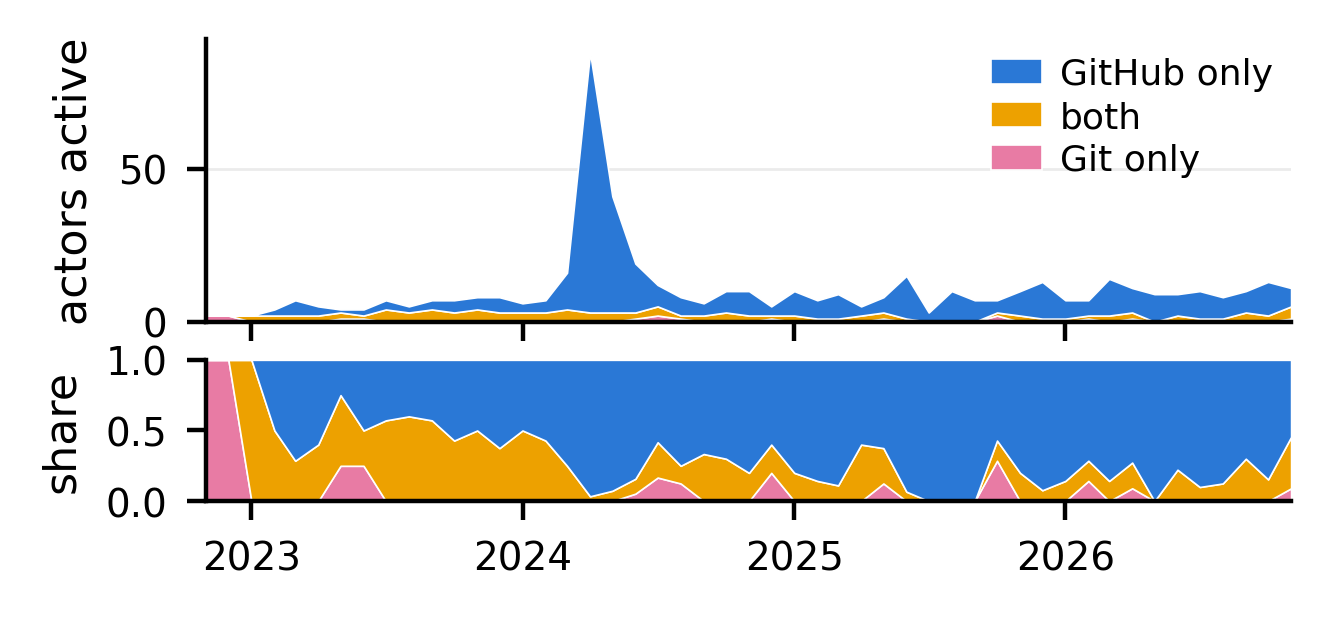

In [8]:
fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(3.5, 1.5), sharex=True, dpi=400,
    gridspec_kw={"hspace": .18, "height_ratios": [2, 1]})

top.stackplot(times, *series.values(), colors=[COLOR[k] for k in series],
              labels=list(series), edgecolor="white", linewidth=.3)
top.set_ylabel("actors active", fontsize=8)
top.set_ylim(0, None)
# Activity is low at the right of the series, so the upper right is free
top.legend(loc="upper right", frameon=False, fontsize=6.5, reverse=True,
           labelspacing=.25, handlelength=1.4, handletextpad=.5, borderpad=0)

totals = [sum(c[1:]) for c in counts]
shares = {k: [v / t for v, t in zip(values, totals)]
          for k, values in series.items()}
bottom.stackplot(times, *shares.values(), colors=[COLOR[k] for k in series],
                 edgecolor="white", linewidth=.3)
bottom.set_ylabel("share", fontsize=8)
bottom.set_ylim(0, 1)
bottom.set_yticks([0, .5, 1])

for ax in (top, bottom):
    ax.set_xlim(times[0], times[-1])
    ax.grid(axis="y", alpha=.25, linewidth=.5)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=7)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
bottom.xaxis.set_major_locator(mdates.YearLocator())
bottom.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.savefig(FIGURE, bbox_inches="tight")
print(f"Saved {FIGURE}")
plt.show()

In [7]:
median = lambda values: sorted(values)[len(values) // 2]
print(f"median month: {median(series['Git only'])} Git only, "
      f"{median(series['GitHub only'])} GitHub only, "
      f"{median(series['both'])} both")
print(f"months with any Git-only actor: "
      f"{sum(1 for v in series['Git only'] if v)} of {len(counts)}")

median month: 0 Git only, 6 GitHub only, 2 both
months with any Git-only actor: 13 of 49
